# k-Nearest Neighbors Assignment – Real Estate Price Prediction
**Name:** Eli Weiss
**Course:** AIM460 – Quiz 1
**Dataset:** California Housing (`sklearn.datasets.fetch_california_housing`)

**Pipeline:** EDA → cleaning & feature engineering → k-NN from scratch → manual calculations → hyperparameter tuning → comparison with sklearn → curse of dimensionality.

In [1]:
# Standard data science libraries (all pre-installed in Google Colab)
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor

# Fixed random seed so every run gives the same results
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style('whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

---
# Part 1: Data Loading and Exploration
## 1.1 Data Loading and Initial Inspection

In [2]:
# Load the dataset from sklearn (downloads automatically the first time)
housing = fetch_california_housing()

# Build a DataFrame with the proper feature names and add the target column
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df['MedHouseVal'] = housing.target

# Save a copy of the raw data as CSV (this file is also in the GitHub folder)
df.to_csv('california_housing.csv', index=False)

print('Dataset shape:', df.shape)
df.head()

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,2401.000,2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


In [3]:
df.tail()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.560,25.000,5.045,1.133,845.000,2.561,39.480,-121.090,0.781
20636,2.557,18.000,6.114,1.316,356.000,3.123,39.490,-121.210,0.771
20637,1.700,17.000,5.206,1.120,1007.000,2.326,39.430,-121.220,0.923
20638,1.867,18.000,5.330,1.172,741.000,2.123,39.430,-121.320,0.847
20639,2.389,16.000,5.255,1.162,1387.000,2.617,39.370,-121.240,0.894


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000
mean,3.871,28.639,5.429,1.097,1425.477,3.071,35.632,-119.570,2.069
std,1.900,12.586,2.474,0.474,1132.462,10.386,2.136,2.004,1.154
min,0.500,1.000,0.846,0.333,3.000,0.692,32.540,-124.350,0.150
25%,2.563,18.000,4.441,1.006,787.000,2.430,33.930,-121.800,1.196
50%,3.535,29.000,5.229,1.049,1166.000,2.818,34.260,-118.490,1.797
75%,4.743,37.000,6.052,1.100,1725.000,3.282,37.710,-118.010,2.647
max,15.000,52.000,141.909,34.067,35682.000,1243.333,41.950,-114.310,5.000


**Target variable:** `MedHouseVal`, the median house value of a block group in units of $100,000. It is continuous, so this is a **regression** problem.

**Feature types:** all 8 features are continuous numeric (`float64`). There are no categorical features. `Latitude`/`Longitude` are geographic coordinates. The other features are block-level averages or counts.

## 1.2 Exploratory Data Analysis
### A. Target Variable Analysis

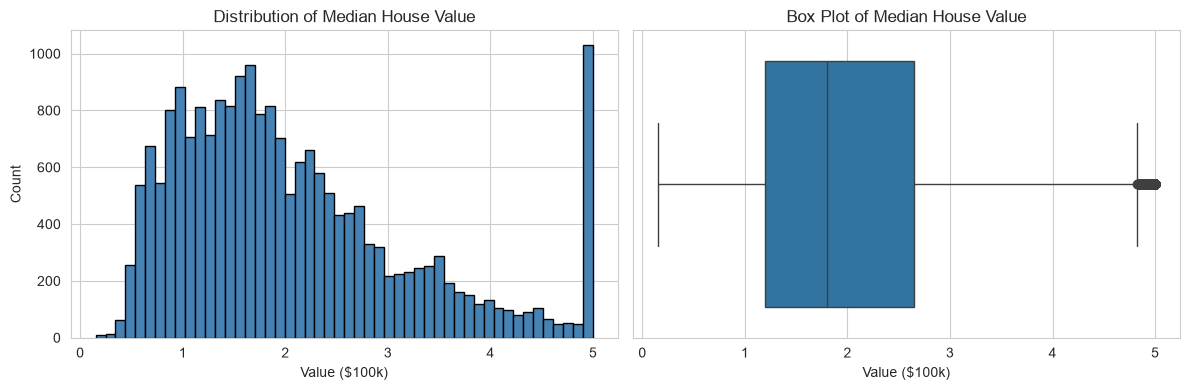

count   20640.000
mean        2.069
std         1.154
min         0.150
25%         1.196
50%         1.797
75%         2.647
max         5.000
Name: MedHouseVal, dtype: float64
Skewness: 0.978
Upper IQR fence: 4.824 -> 1071 outliers above it
Houses at the 5.0 cap: 992


In [6]:
target = 'MedHouseVal'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df[target], bins=50, color='steelblue', edgecolor='black')
axes[0].set_title('Distribution of Median House Value')
axes[0].set_xlabel('Value ($100k)')
axes[0].set_ylabel('Count')
sns.boxplot(x=df[target], ax=axes[1])
axes[1].set_title('Box Plot of Median House Value')
axes[1].set_xlabel('Value ($100k)')
plt.tight_layout()
plt.show()

print(df[target].describe())
print('Skewness:', round(df[target].skew(), 3))

# Count target outliers using the 1.5*IQR rule, and houses sitting at the 5.0 cap
q1, q3 = df[target].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print(f'Upper IQR fence: {upper_fence:.3f} -> {(df[target] > upper_fence).sum()} outliers above it')
print('Houses at the 5.0 cap:', (df[target] >= 5.0).sum())

**Interpretation:** prices are **right-skewed**. The median is about \$180k and the mean is about \$207k, with a long tail toward expensive areas. There is a large spike at **5.0 (\$500k)**. The dataset was **capped** at that value, so those ~1,000 "outliers" are not data errors. Their true value is just unknown (≥ \$500k). I keep them because removing them would throw away all of the most expensive areas. The model will tend to under-predict them, since it can never predict above 5.0.

### B. Feature Analysis

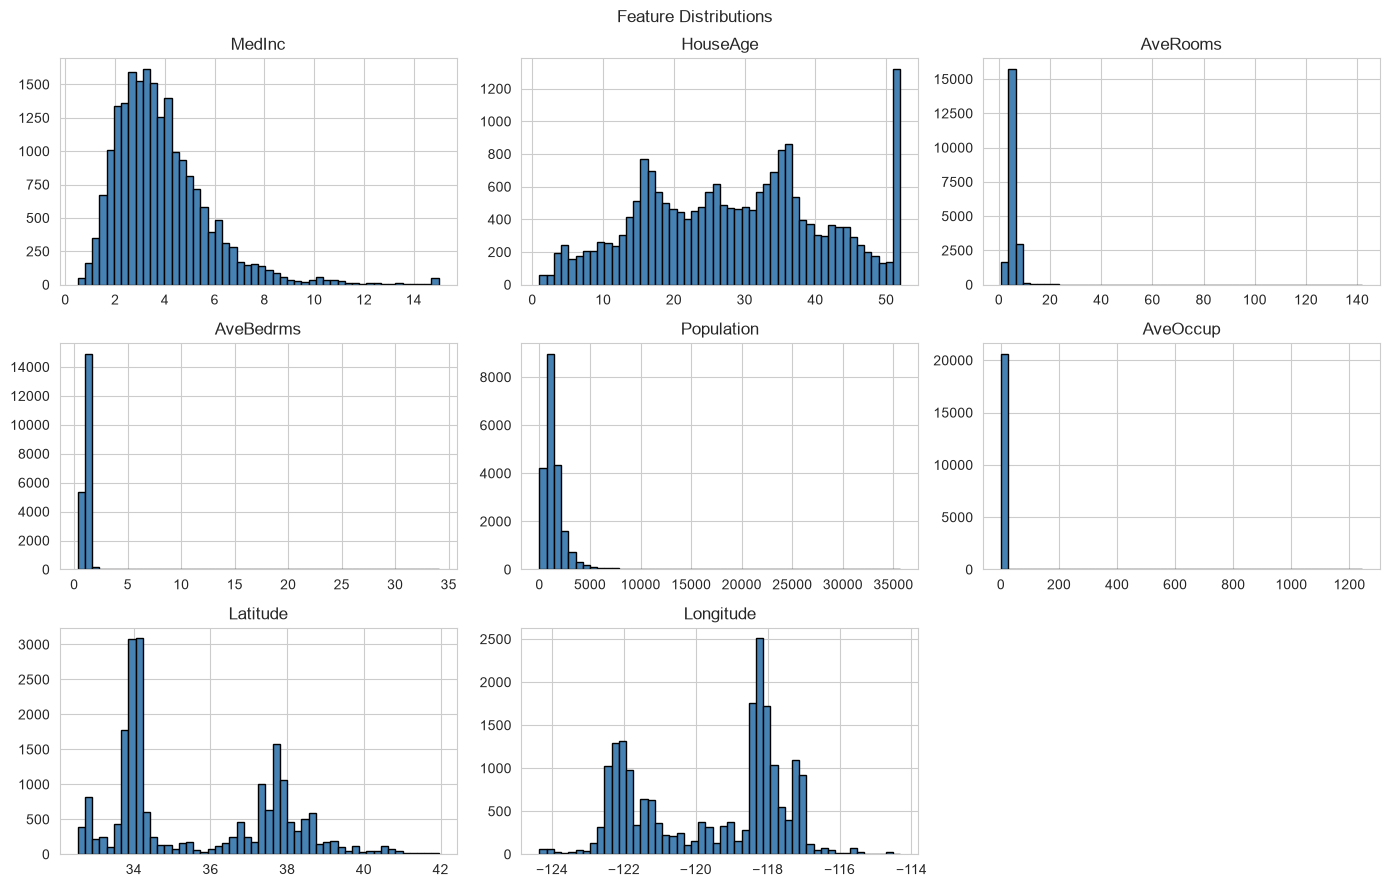

In [7]:
features = list(housing.feature_names)

df[features].hist(bins=50, figsize=(14, 9), color='steelblue', edgecolor='black')
plt.suptitle('Feature Distributions')
plt.tight_layout()
plt.show()

In [8]:
# Skewness of each feature: |skew| > 1 is usually considered highly skewed
print(df[features].skew().sort_values(ascending=False))

AveOccup     97.640
AveBedrms    31.317
AveRooms     20.698
Population    4.936
MedInc        1.647
Latitude      0.466
HouseAge      0.060
Longitude    -0.298
dtype: float64


**Skewed features:** `AveRooms`, `AveBedrms`, `AveOccup` and `Population` are **extremely right-skewed**. A few block groups have huge values (e.g. `AveOccup` > 1000, probably dorms, prisons or resorts). `MedInc` is moderately skewed. Possible fixes are a **log transform** or **removing extreme outliers**. Since k-NN uses distances, these extreme values would also stretch the feature scales, so they get handled in Part 2. `HouseAge`, `Latitude` and `Longitude` are not skewed (latitude/longitude are bimodal: the LA and SF regions).

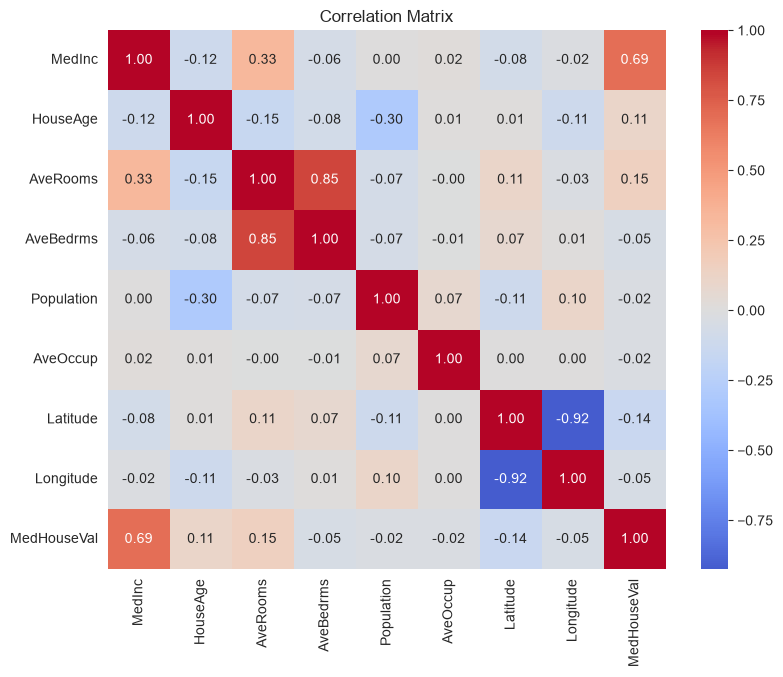

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

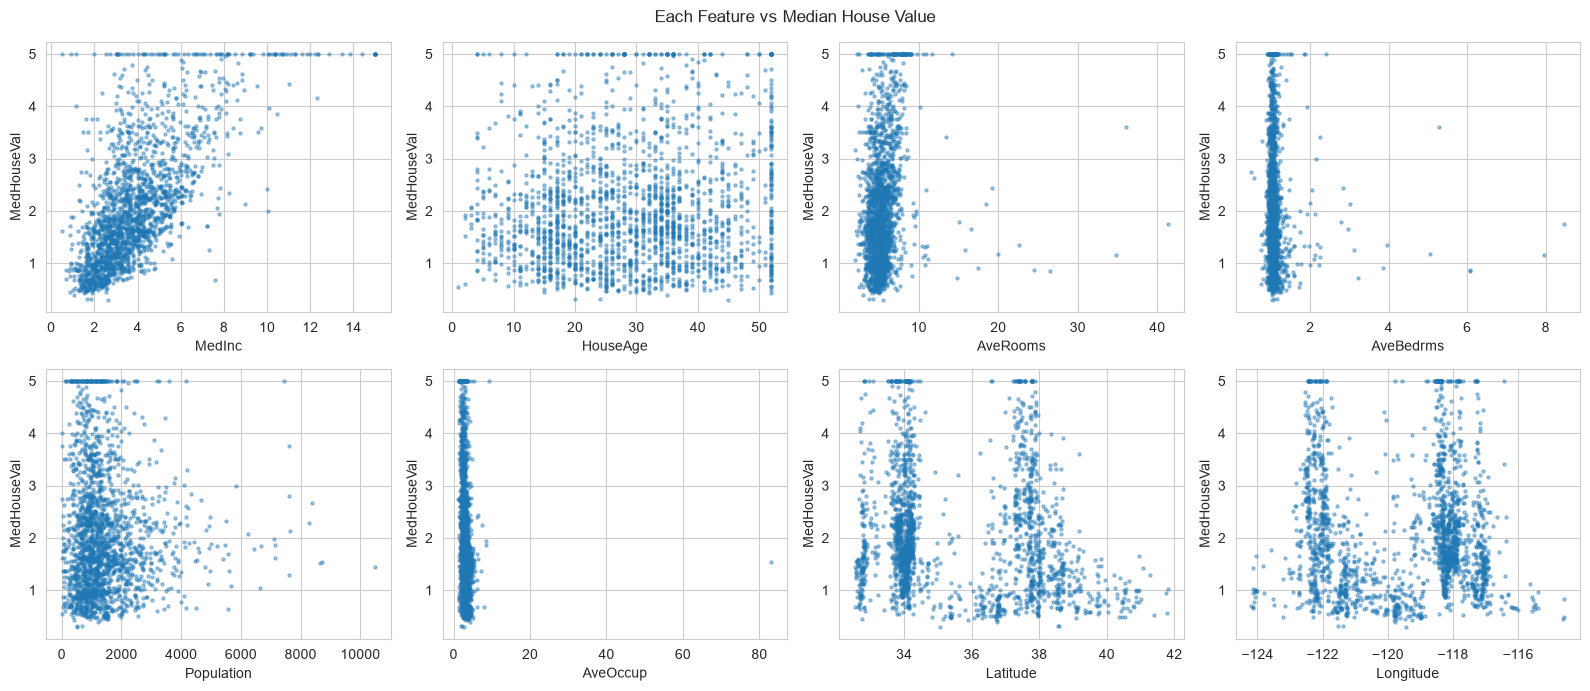

In [10]:
# Scatter plot of every feature vs the target
# (a random sample of 2,000 rows keeps the plots readable)
sample = df.sample(2000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    ax.scatter(sample[col], sample[target], s=5, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel(target)
plt.suptitle('Each Feature vs Median House Value')
plt.tight_layout()
plt.show()

### C. Geographic Analysis

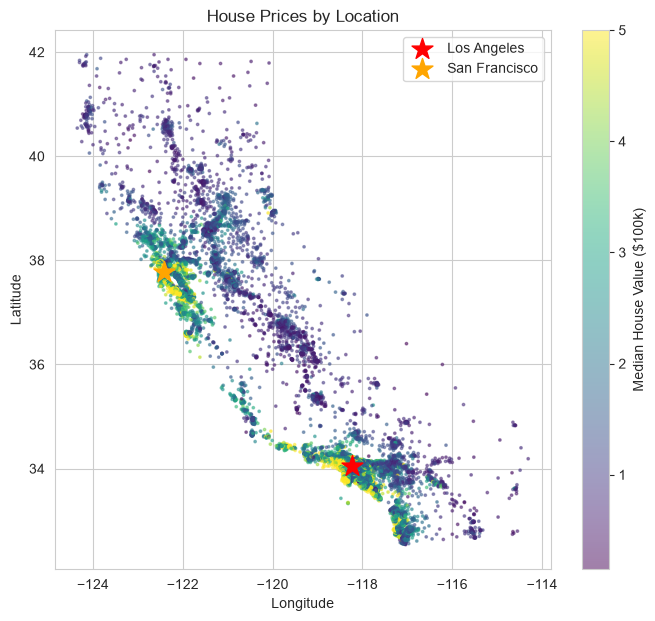

In [11]:
plt.figure(figsize=(8, 7))
sc = plt.scatter(df['Longitude'], df['Latitude'], c=df[target], cmap='viridis', s=3, alpha=0.5)
plt.colorbar(sc, label='Median House Value ($100k)')
# Mark the two major cities for reference
plt.scatter(-118.2437, 34.0522, c='red', marker='*', s=250, label='Los Angeles')
plt.scatter(-122.4194, 37.7749, c='orange', marker='*', s=250, label='San Francisco')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('House Prices by Location')
plt.legend()
plt.show()

**Geographic patterns:** the most expensive homes (yellow) are along the **coast**, especially around the **San Francisco Bay Area** and **Los Angeles / San Diego**. Inland areas such as the Central Valley and the desert in the east are much cheaper. Housing in California is driven by closeness to the ocean and to big job centers, plus the limited land in those coastal cities. Latitude and longitude barely correlate with price *linearly*, but location is clearly very important. k-NN can capture this well, because nearby points in lat/long space have similar prices.

### D. Feature Relationships

MedInc      0.688
AveRooms    0.152
Latitude   -0.144
Name: MedHouseVal, dtype: float64


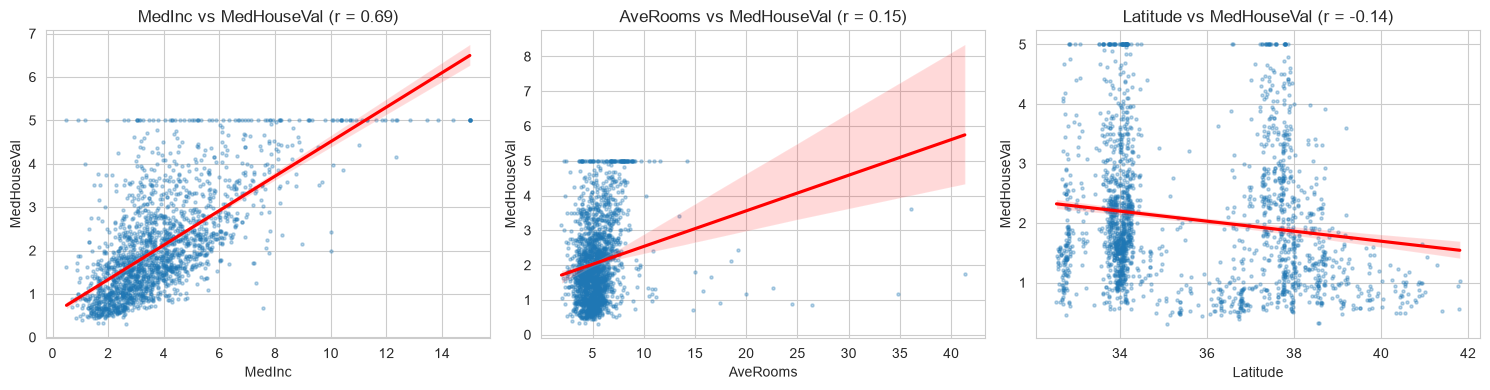

In [12]:
# Top 3 features by absolute correlation with the target
corr_with_target = df.corr()[target].drop(target)
top3 = corr_with_target.abs().sort_values(ascending=False).head(3).index
print(corr_with_target[top3])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, top3):
    sns.regplot(x=col, y=target, data=sample, ax=ax,
                scatter_kws={'s': 5, 'alpha': 0.3}, line_kws={'color': 'red'})
    ax.set_title(f'{col} vs {target} (r = {corr_with_target[col]:.2f})')
plt.tight_layout()
plt.show()

In [13]:
# Multicollinearity: list feature pairs with |correlation| > 0.5
corr = df[features].corr()
pairs = []
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        if abs(corr.iloc[i, j]) > 0.5:
            pairs.append((features[i], features[j], round(corr.iloc[i, j], 3)))
pd.DataFrame(pairs, columns=['Feature 1', 'Feature 2', 'Correlation'])

,Feature 1,Feature 2,Correlation
0,AveRooms,AveBedrms,0.848
1,Latitude,Longitude,-0.925


**Multicollinearity:** `AveRooms` and `AveBedrms` are strongly correlated (both measure house size), and `Latitude` and `Longitude` are strongly negatively correlated (because California runs diagonally from NW to SE). For k-NN, correlated features effectively count the same information twice in the distance. That gives "house size" extra weight in deciding who the neighbors are.

### EDA Summary
**Income is the strongest single predictor of house price.** `MedInc` has a correlation of about 0.69 with the target, far more than any other feature, and the trend is clearly positive. Location is the other big factor. The map shows expensive clusters along the coast near SF and LA and much cheaper prices inland. Latitude and longitude have weak *linear* correlations with price, but the relationship is very strong *non-linearly*. That is a good case for k-NN, which predicts from similar nearby points instead of fitting a line.

**There are several challenges for modeling.** First, the target is capped at \$500k, so the model can never predict above 5.0 and will under-estimate the most expensive areas. Second, `AveRooms`, `AveBedrms`, `AveOccup` and `Population` are extremely skewed, with a few huge values. Since k-NN uses distances, those values would dominate unless we remove outliers and **scale** the features. Third, the features are on very different scales (Population is in the thousands, MedInc is around 1–15), so scaling is required. Without it, Population alone would decide the neighbors.

**Some features are redundant.** `AveRooms`/`AveBedrms` and `Latitude`/`Longitude` are strongly correlated. Several features (`Population`, `AveBedrms`) have almost no relationship with price, and those just add noise to the distance calculation. This hints at the curse of dimensionality explored in Part 6: more features are not always better for k-NN.

---
# Part 2: Data Cleaning and Preprocessing
## 2.1 Missing Value Analysis

In [14]:
print(df.isnull().sum())
print('\nTotal missing values:', df.isnull().sum().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total missing values: 0


**Decision:** there are **no missing values**, so no imputation or row removal is needed.

## 2.2 Outlier Detection and Handling

In [15]:
def detect_outliers_iqr(data, column, factor=1.5):
    """
    Detect outliers using the IQR method.

    Parameters:
    data: DataFrame
    column: column name to check
    factor: IQR multiplier (default 1.5)

    Returns:
    Boolean series indicating outliers (True = outlier)
    """
    # Q1 and Q3 are the 25th and 75th percentiles; IQR is the middle 50% range
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    # Any value more than factor * IQR below Q1 or above Q3 is an outlier
    lower = q1 - factor * iqr
    upper = q3 + factor * iqr
    return (data[column] < lower) | (data[column] > upper)


def detect_outliers_zscore(data, column, threshold=3):
    """
    Detect outliers using the Z-score method.

    Parameters:
    data: DataFrame
    column: column name to check
    threshold: Z-score threshold (default 3)

    Returns:
    Boolean series indicating outliers (True = outlier)
    """
    # The z-score is how many standard deviations a value is from the mean
    mean = data[column].mean()
    std = data[column].std()
    z = (data[column] - mean) / std
    # Values farther than `threshold` standard deviations away are outliers
    return z.abs() > threshold

In [16]:
# Apply both methods to every feature.
# A row counts as an outlier if it is flagged in ANY feature.
# (The target is left out: its "outliers" are the real, capped $500k homes discussed in 1.2A.)
iqr_any = pd.Series(False, index=df.index)
z_any = pd.Series(False, index=df.index)
counts = []
for col in features:
    iqr_mask = detect_outliers_iqr(df, col)
    z_mask = detect_outliers_zscore(df, col)
    iqr_any = iqr_any | iqr_mask
    z_any = z_any | z_mask
    counts.append([col, iqr_mask.sum(), z_mask.sum()])

outlier_counts = pd.DataFrame(counts, columns=['Feature', 'IQR outliers', 'Z-score outliers'])
print(outlier_counts.to_string(index=False))
print(f'\nRows flagged by IQR (any feature):     {iqr_any.sum():>5} ({iqr_any.mean():.1%} of data)')
print(f'Rows flagged by Z-score (any feature): {z_any.sum():>5} ({z_any.mean():.1%} of data)')

   Feature  IQR outliers  Z-score outliers
    MedInc           681               345
  HouseAge             0                 0
  AveRooms           511               133
 AveBedrms          1424               145
Population          1196               342
  AveOccup           711                 8
  Latitude             0                 0
 Longitude             0                 0

Rows flagged by IQR (any feature):      3798 (18.4% of data)
Rows flagged by Z-score (any feature):   846 (4.1% of data)


**Comparing the two methods:**
- **IQR** flags far more rows. On heavily skewed features like `Population` and `AveRooms`, the long right tail is "normal" for the data, but IQR still flags all of it. Removing that many rows would throw away a large share of real, valid block groups.
- **Z-score** (|z| > 3) only flags the truly **extreme** values, like `AveOccup` of 1,000+ or `AveRooms` of 100+. Those are almost certainly special cases (dorms, resorts, data errors) that would distort distances.

**Decision: use the Z-score method.** It removes the extreme values that would hurt a distance-based model while keeping most of the data. One limitation: the mean and standard deviation used by the z-score are themselves pulled by the outliers, but at threshold 3 that is acceptable here.

Rows before: 20640  |  Rows after: 19794  |  Removed: 846 (4.1%)


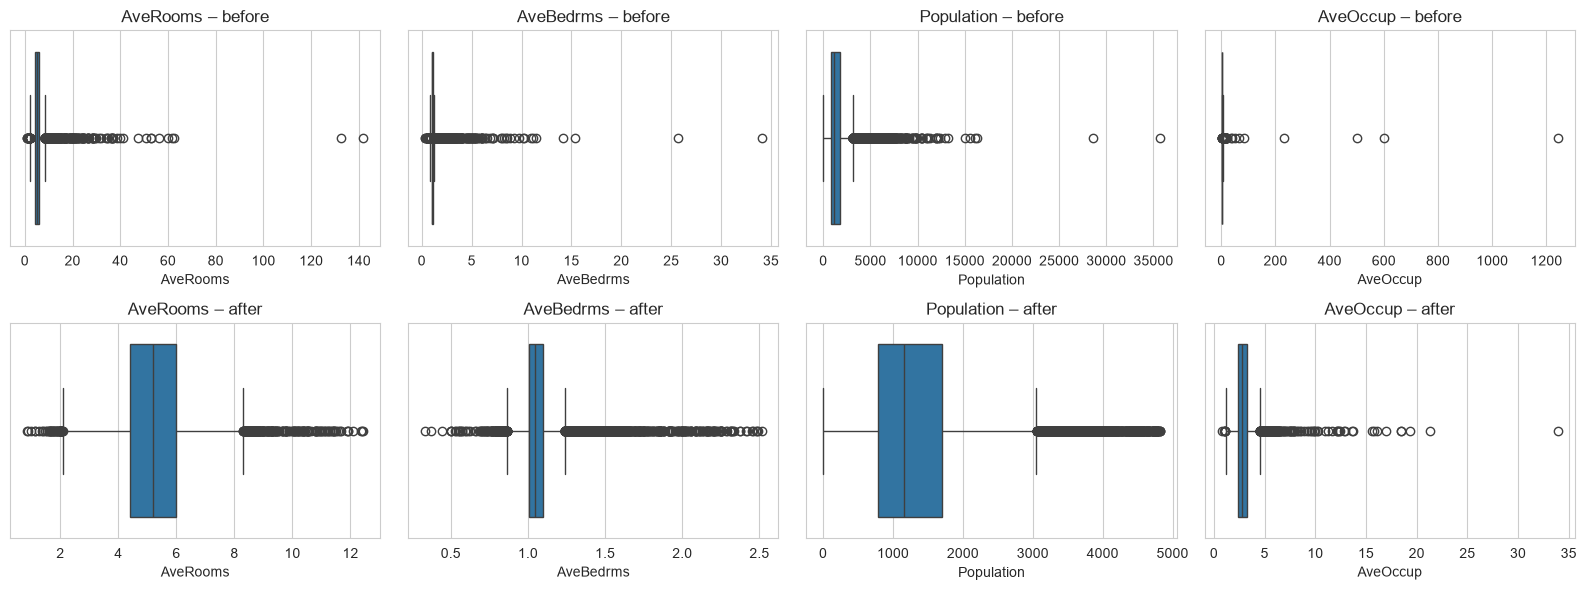

In [17]:
# Remove the rows flagged by the Z-score method
df_clean = df[~z_any].copy()
print(f'Rows before: {len(df)}  |  Rows after: {len(df_clean)}  |  '
      f'Removed: {len(df) - len(df_clean)} ({(len(df) - len(df_clean)) / len(df):.1%})')

# Before vs after box plots for the most skewed features
check_cols = ['AveRooms', 'AveBedrms', 'Population', 'AveOccup']
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, col in enumerate(check_cols):
    sns.boxplot(x=df[col], ax=axes[0, i])
    axes[0, i].set_title(f'{col} – before')
    sns.boxplot(x=df_clean[col], ax=axes[1, i])
    axes[1, i].set_title(f'{col} – after')
plt.tight_layout()
plt.show()

**Impact:** the extreme values are gone and the box plots are far less stretched. Some points still sit outside the whiskers. That's expected, since the Z-score method only removes the most extreme rows, and the remaining spread is real variation. Standard scaling (Part 5.1) handles what's left.

## 2.3 Feature Engineering
Distances to LA and SF use the **haversine formula**, which gives real distance in km on the Earth's surface.

In [18]:
def haversine_km(lat1, lon1, lat2, lon2):
    """
    Great-circle distance in km between two (lat, lon) points.
    Works on single numbers or on whole pandas columns.
    """
    R = 6371  # Earth's radius in km
    # Convert degrees to radians for the trig functions
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


# 1. Ratio features
df_clean['rooms_per_household'] = df_clean['AveRooms'] / df_clean['AveOccup']
df_clean['bedrooms_per_room'] = df_clean['AveBedrms'] / df_clean['AveRooms']
df_clean['population_per_household'] = df_clean['Population'] / df_clean['AveOccup']

# 2. Geographic features
df_clean['distance_to_LA'] = haversine_km(df_clean['Latitude'], df_clean['Longitude'], 34.0522, -118.2437)
df_clean['distance_to_SF'] = haversine_km(df_clean['Latitude'], df_clean['Longitude'], 37.7749, -122.4194)
df_clean['coastal_proximity'] = (df_clean['Longitude'] > -121).astype(int)

# 3. Categorical features (right=False means each bin includes its left edge, e.g. 3 is "Medium")
df_clean['income_category'] = pd.cut(df_clean['MedInc'], bins=[0, 3, 6, 9, np.inf],
                                     labels=['Low', 'Medium', 'High', 'Very High'], right=False)
df_clean['house_age_category'] = pd.cut(df_clean['HouseAge'], bins=[0, 10, 30, np.inf],
                                        labels=['New', 'Medium', 'Old'], right=False)

df_clean.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,rooms_per_household,bedrooms_per_room,population_per_household,distance_to_LA,distance_to_SF,coastal_proximity,income_category,house_age_category
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526,2.733,0.147,126.000,556.531,20.330,0,High,Old
1,8.301,21.000,6.238,0.972,2401.000,2.110,37.860,-122.220,3.585,2.957,0.156,1138.000,554.282,19.908,0,High,Medium
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521,2.958,0.130,177.000,554.613,17.835,0,High,Old
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413,2.283,0.184,219.000,555.196,17.064,0,Medium,Old
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422,2.880,0.172,259.000,555.196,17.064,0,Medium,Old


In [19]:
# Quick check that the new features are meaningful
print(df_clean.groupby('income_category', observed=True)[target].agg(['mean', 'count']), '\n')
print(df_clean.groupby('house_age_category', observed=True)[target].agg(['mean', 'count']), '\n')

new_features = ['rooms_per_household', 'bedrooms_per_room', 'population_per_household',
                'distance_to_LA', 'distance_to_SF', 'coastal_proximity']
print('Correlation of new features with target:')
print(df_clean[new_features + [target]].corr()[target].drop(target).round(3))

                 mean  count
income_category             
Low             1.337   7219
Medium          2.200  10605
High            3.581   1911
Very High       4.757     59 

                    mean  count
house_age_category             
New                1.969   1115
Medium             1.943   8904
Old                2.108   9775 

Correlation of new features with target:
rooms_per_household         0.393
bedrooms_per_room          -0.211
population_per_household    0.099
distance_to_LA             -0.130
distance_to_SF             -0.031
coastal_proximity          -0.055
Name: MedHouseVal, dtype: float64


**Notes:**
- Mean price rises clearly with `income_category`, which confirms income is the key driver.
- `coastal_proximity` is built exactly as specified (longitude > -121). Note that this rule actually marks the **southern/eastern** part of the state (including LA and the inland desert), so it is a rough "south vs. north" flag rather than a true coastal flag.
- **Features used for k-NN:** the 8 original features plus the 6 numeric engineered features (14 total). The two **categorical** features are left out of the model. They are just binned versions of `MedInc`/`HouseAge`, which are already included, and k-NN distances need numeric inputs.

In [20]:
model_features = features + new_features
X = df_clean[model_features].values
y = df_clean[target].values
print('X shape:', X.shape, '| y shape:', y.shape)
print('Model features:', model_features)

X shape: (19794, 14) | y shape: (19794,)
Model features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'distance_to_LA', 'distance_to_SF', 'coastal_proximity']


---
# Part 3: Custom k-NN Implementation
## 3.1 Distance Metrics
Each function sums over the last axis (`axis=-1`). The same function then works for **two points** (returns one number) and for **one point vs. a whole array of points** (returns one distance per row). That lets k-NN compute all distances at once with numpy instead of a slow Python loop.

In [21]:
def _check_same_length(point1, point2):
    """Convert inputs to float arrays and make sure they have the same number of features."""
    point1 = np.asarray(point1, dtype=float)
    point2 = np.asarray(point2, dtype=float)
    if point1.shape[-1] != point2.shape[-1]:
        raise ValueError(f'Points have different lengths: {point1.shape[-1]} vs {point2.shape[-1]}')
    return point1, point2


def euclidean_distance(point1, point2):
    """
    Calculate Euclidean distance between two points: sqrt(sum((a - b)^2))

    Parameters:
    point1, point2: numpy arrays of equal length

    Returns:
    float: Euclidean distance
    """
    point1, point2 = _check_same_length(point1, point2)
    # Square each feature difference, add them up, then take the square root
    return np.sqrt(np.sum((point1 - point2) ** 2, axis=-1))


def manhattan_distance(point1, point2):
    """
    Calculate Manhattan distance between two points: sum(|a - b|)

    Parameters:
    point1, point2: numpy arrays of equal length

    Returns:
    float: Manhattan distance
    """
    point1, point2 = _check_same_length(point1, point2)
    # Add up the absolute difference in each feature ("city block" distance)
    return np.sum(np.abs(point1 - point2), axis=-1)


def minkowski_distance(point1, point2, p=2):
    """
    Calculate Minkowski distance between two points: (sum(|a - b|^p))^(1/p)

    Parameters:
    point1, point2: numpy arrays of equal length
    p: parameter (p=1 gives Manhattan, p=2 gives Euclidean)

    Returns:
    float: Minkowski distance
    """
    if p <= 0:
        raise ValueError('p must be positive')
    point1, point2 = _check_same_length(point1, point2)
    # Raise each absolute difference to the power p, sum, then take the p-th root
    return np.sum(np.abs(point1 - point2) ** p, axis=-1) ** (1 / p)


# Quick sanity check with a 3-4-5 triangle
a, b = np.array([0, 0]), np.array([3, 4])
print('Euclidean:', euclidean_distance(a, b))           # expect 5
print('Manhattan:', manhattan_distance(a, b))           # expect 7
print('Minkowski p=1:', minkowski_distance(a, b, p=1))  # expect 7 (same as Manhattan)
print('Minkowski p=2:', minkowski_distance(a, b, p=2))  # expect 5 (same as Euclidean)

Euclidean: 5.0
Manhattan: 7.0
Minkowski p=1: 7.0
Minkowski p=2: 5.0


## 3.2 k-NN Class

In [22]:
class CustomKNN:
    """k-Nearest Neighbors regressor written from scratch."""

    def __init__(self, k=5, distance_metric='euclidean', weights='uniform', p=3):
        """
        Custom k-NN implementation

        Parameters:
        k: number of neighbors
        distance_metric: 'euclidean', 'manhattan', or 'minkowski'
        weights: 'uniform' or 'distance'
        p: power for the Minkowski distance (only used if distance_metric='minkowski')
        """
        # Validate the settings right away so mistakes are caught early
        if not isinstance(k, (int, np.integer)) or k < 1:
            raise ValueError('k must be a positive integer')
        if distance_metric not in ('euclidean', 'manhattan', 'minkowski'):
            raise ValueError("distance_metric must be 'euclidean', 'manhattan', or 'minkowski'")
        if weights not in ('uniform', 'distance'):
            raise ValueError("weights must be 'uniform' or 'distance'")

        self.k = k
        self.distance_metric = distance_metric
        self.weights = weights
        self.p = p
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        """Store training data. k-NN is a 'lazy learner': no real training happens."""
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2:
            raise ValueError('X must be a 2D array (samples x features)')
        if len(X) != len(y):
            raise ValueError('X and y must have the same number of samples')
        if self.k > len(X):
            raise ValueError(f'k={self.k} is larger than the number of training samples ({len(X)})')
        self.X_train = X
        self.y_train = y
        return self  # returning self allows chaining: CustomKNN().fit(X, y).predict(...)

    def _calculate_distance(self, point1, point2):
        """Calculate distance based on the selected metric."""
        if self.distance_metric == 'euclidean':
            return euclidean_distance(point1, point2)
        elif self.distance_metric == 'manhattan':
            return manhattan_distance(point1, point2)
        else:
            return minkowski_distance(point1, point2, p=self.p)

    def _get_neighbors(self, test_point):
        """
        Find the k nearest neighbors for a test point.
        Returns the indices of the k nearest training points and their distances.
        """
        # Distance from the test point to EVERY training point (one vectorized call)
        distances = self._calculate_distance(self.X_train, test_point)
        # argsort gives indices ordered from smallest to largest distance; keep the first k
        # (kind='stable' means ties keep their original order, so results are repeatable)
        nearest_idx = np.argsort(distances, kind='stable')[:self.k]
        return nearest_idx, distances[nearest_idx]

    def predict_single(self, test_point):
        """Predict the target for a single test point (uniform or distance-weighted)."""
        if self.X_train is None:
            raise RuntimeError('Model is not fitted yet. Call fit() first.')
        test_point = np.asarray(test_point, dtype=float)
        if test_point.shape != (self.X_train.shape[1],):
            raise ValueError(f'Test point must have {self.X_train.shape[1]} features')

        idx, dists = self._get_neighbors(test_point)
        neighbor_targets = self.y_train[idx]

        if self.weights == 'uniform':
            # Every neighbor counts equally: plain average
            return np.mean(neighbor_targets)

        # Distance weighting: weight = 1 / distance, so closer neighbors count more.
        # If a neighbor is at distance 0 (exact match), 1/0 is undefined, so we
        # return the average of the exact matches (same behavior as sklearn).
        if np.any(dists == 0):
            return np.mean(neighbor_targets[dists == 0])
        w = 1 / dists
        return np.sum(w * neighbor_targets) / np.sum(w)

    def predict(self, X_test):
        """Predict for multiple test points."""
        if self.X_train is None:
            raise RuntimeError('Model is not fitted yet. Call fit() first.')
        X_test = np.asarray(X_test, dtype=float)
        if X_test.ndim != 2 or X_test.shape[1] != self.X_train.shape[1]:
            raise ValueError(f'X_test must be 2D with {self.X_train.shape[1]} features')
        return np.array([self.predict_single(x) for x in X_test])

    def score(self, X_test, y_test):
        """Calculate the R-squared score: 1 - SS_residual / SS_total."""
        y_test = np.asarray(y_test, dtype=float)
        y_pred = self.predict(X_test)
        ss_res = np.sum((y_test - y_pred) ** 2)           # error left over by the model
        ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)  # error of always guessing the mean
        return 1 - ss_res / ss_tot

In [23]:
# Small test: 1D data where y = x. The 2 nearest neighbors of 2.4 are 2 and 3.
X_toy = np.array([[1], [2], [3], [10]])
y_toy = np.array([1, 2, 3, 10])
toy_u = CustomKNN(k=2, weights='uniform').fit(X_toy, y_toy)
toy_d = CustomKNN(k=2, weights='distance').fit(X_toy, y_toy)
print('Uniform prediction for 2.4: ', toy_u.predict_single([2.4]))   # (2 + 3) / 2 = 2.5
print('Distance prediction for 2.4:', round(toy_d.predict_single([2.4]), 3))  # closer to 2

# Error handling check
try:
    CustomKNN(k=0)
except ValueError as e:
    print('Caught error:', e)

Uniform prediction for 2.4:  2.5
Distance prediction for 2.4: 2.4
Caught error: k must be a positive integer


---
# Part 4: Manual Calculations
## 4.1 Distance Calculations
To keep the hand calculation manageable, I use **4 features** (`MedInc`, `HouseAge`, `AveRooms`, `AveOccup`) of the first 3 houses, rounded to 2 decimals. These are the raw (unscaled) values. The hand-written version is in the GitHub folder (`manual_calculations.jpg`).

**Formulas:**
- Euclidean: $d(a,b) = \sqrt{\sum_{i=1}^{n}(a_i - b_i)^2}$
- Manhattan: $d(a,b) = \sum_{i=1}^{n}|a_i - b_i|$
- Minkowski: $d(a,b) = \left(\sum_{i=1}^{n}|a_i - b_i|^p\right)^{1/p}$

In [24]:
calc_features = ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup']
points = df_clean[calc_features].iloc[[0, 1, 2]].round(2)
points.index = ['Point 1', 'Point 2', 'Point 3']
points

,MedInc,HouseAge,AveRooms,AveOccup
Point 1,8.330,41.000,6.980,2.560
Point 2,8.300,21.000,6.240,2.110
Point 3,7.260,52.000,8.290,2.800


In [25]:
p1, p2, p3 = points.values


def show_steps(a, b, p, title):
    """Print every step of a Minkowski-style distance calculation (p=1 Manhattan, p=2 Euclidean)."""
    print(title)
    diffs = np.abs(a - b)
    for name, x1, x2, d in zip(calc_features, a, b, diffs):
        print(f'  {name:9}: |{x1:.2f} - {x2:.2f}| = {d:.2f}  ->  {d:.2f}^{p} = {d ** p:.4f}')
    total = np.sum(diffs ** p)
    print(f'  Sum = {total:.4f}')
    print(f'  Distance = ({total:.4f})^(1/{p}) = {total ** (1 / p):.4f}\n')


show_steps(p1, p2, 2, '1) Euclidean distance between Point 1 and Point 2')
show_steps(p1, p3, 1, '2) Manhattan distance between Point 1 and Point 3')
show_steps(p2, p3, 3, '3) Minkowski distance (p=3) between Point 2 and Point 3')

# Verify with the functions from Part 3
print('Verification with my functions:')
print(f'  euclidean_distance(P1, P2)       = {euclidean_distance(p1, p2):.4f}')
print(f'  manhattan_distance(P1, P3)       = {manhattan_distance(p1, p3):.4f}')
print(f'  minkowski_distance(P2, P3, p=3)  = {minkowski_distance(p2, p3, p=3):.4f}')

1) Euclidean distance between Point 1 and Point 2
  MedInc   : |8.33 - 8.30| = 0.03  ->  0.03^2 = 0.0009
  HouseAge : |41.00 - 21.00| = 20.00  ->  20.00^2 = 400.0000
  AveRooms : |6.98 - 6.24| = 0.74  ->  0.74^2 = 0.5476
  AveOccup : |2.56 - 2.11| = 0.45  ->  0.45^2 = 0.2025
  Sum = 400.7510
  Distance = (400.7510)^(1/2) = 20.0188

2) Manhattan distance between Point 1 and Point 3
  MedInc   : |8.33 - 7.26| = 1.07  ->  1.07^1 = 1.0700
  HouseAge : |41.00 - 52.00| = 11.00  ->  11.00^1 = 11.0000
  AveRooms : |6.98 - 8.29| = 1.31  ->  1.31^1 = 1.3100
  AveOccup : |2.56 - 2.80| = 0.24  ->  0.24^1 = 0.2400
  Sum = 13.6200
  Distance = (13.6200)^(1/1) = 13.6200

3) Minkowski distance (p=3) between Point 2 and Point 3
  MedInc   : |8.30 - 7.26| = 1.04  ->  1.04^3 = 1.1249
  HouseAge : |21.00 - 52.00| = 31.00  ->  31.00^3 = 29791.0000
  AveRooms : |6.24 - 8.29| = 2.05  ->  2.05^3 = 8.6151
  AveOccup : |2.11 - 2.80| = 0.69  ->  0.69^3 = 0.3285
  Sum = 29801.0685
  Distance = (29801.0685)^(1/3) 

**Observation:** `HouseAge` differences (e.g. 41 vs 21) completely dominate these unscaled distances. The income difference barely matters. This is exactly why the features must be **scaled** before running k-NN.

## 4.2 k-NN Prediction Walkthrough
First I create the **80/20 train/test split** and apply **StandardScaler**. This split is used for the rest of the notebook, and Part 5.1 compares and justifies the scaler choice. The scaler is fit on the training data only, so no information from the test set leaks into training.

In [26]:
# 80/20 train-test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

# Fit the scaler on the training data only, then apply it to both sets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (15835, 14) | Test: (3959, 14)


In [27]:
# Pick the first test point
test_point = X_test[0]
print('Test point (scaled):', np.round(test_point, 2))
print(f'Actual target value: {y_test[0]:.3f}\n')

# Distance from the test point to ALL training points (Euclidean)
all_distances = euclidean_distance(X_train, test_point)
print(f'Computed {len(all_distances)} distances (one per training point).\n')

# Show the first 10 calculations (first 3 of the 14 terms written out)
print('First 10 distance calculations:')
for i in range(10):
    diff = test_point - X_train[i]
    terms = ' + '.join(f'({test_point[j]:.2f} - {X_train[i][j]:.2f})²' for j in range(3))
    print(f'Train point {i}: √[{terms} + ... (14 terms)] = √{np.sum(diff ** 2):.3f} = {all_distances[i]:.3f}')

Test point (scaled): [ 2.95  0.48  1.27 -0.2   0.64 -0.27  0.74 -1.18  1.05 -1.07  0.74  0.87
 -1.23 -1.36]
Actual target value: 5.000

Computed 15835 distances (one per training point).

First 10 distance calculations:
Train point 0: √[(2.95 - -1.09)² + (0.48 - 1.13)² + (1.27 - -0.50)² + ... (14 terms)] = √36.970 = 6.080
Train point 1: √[(2.95 - -0.52)² + (0.48 - -1.37)² + (1.27 - -1.30)² + ... (14 terms)] = √51.795 = 7.197
Train point 2: √[(2.95 - -0.95)² + (0.48 - 0.40)² + (1.27 - 0.39)² + ... (14 terms)] = √31.445 = 5.608
Train point 3: √[(2.95 - -0.14)² + (0.48 - 0.64)² + (1.27 - 0.50)² + ... (14 terms)] = √11.728 = 3.425
Train point 4: √[(2.95 - -1.45)² + (0.48 - -1.37)² + (1.27 - -1.15)² + ... (14 terms)] = √52.232 = 7.227
Train point 5: √[(2.95 - 0.03)² + (0.48 - 0.96)² + (1.27 - 0.63)² + ... (14 terms)] = √13.333 = 3.651
Train point 6: √[(2.95 - -0.19)² + (0.48 - 1.05)² + (1.27 - -0.35)² + ... (14 terms)] = √38.719 = 6.222
Train point 7: √[(2.95 - -0.20)² + (0.48 - -1.29)² + (

In [28]:
# Rank ALL training points by distance (smallest first) and keep the top 5
ranking = np.argsort(all_distances, kind='stable')
top5 = ranking[:5]
neighbors = pd.DataFrame({
    'Rank': range(1, 6),
    'Train Index': top5,
    'Distance': all_distances[top5],
    'Target': y_train[top5],
})
print('5 Nearest Neighbors:')
print(neighbors.to_string(index=False))

5 Nearest Neighbors:
 Rank  Train Index  Distance  Target
    1         1482     0.719   4.764
    2         9716     0.804   3.997
    3         7286     0.847   5.000
    4         9092     0.911   5.000
    5         4328     0.913   5.000


In [29]:
t = y_train[top5]          # neighbor targets
d = all_distances[top5]    # neighbor distances

# Uniform prediction: simple average of the 5 targets
uniform_pred = np.sum(t) / 5
print('Uniform prediction:')
print('  (' + ' + '.join(f'{v:.3f}' for v in t) + f') / 5 = {uniform_pred:.4f}\n')

# Distance-weighted prediction: weight = 1/distance, prediction = sum(w*target) / sum(w)
w = 1 / d
print('Distance-weighted prediction:')
for i in range(5):
    print(f'  Neighbor {i + 1}: w = 1/{d[i]:.4f} = {w[i]:.4f},  w × target = {w[i]:.4f} × {t[i]:.3f} = {w[i] * t[i]:.4f}')
weighted_pred = np.sum(w * t) / np.sum(w)
print(f'  Prediction = {np.sum(w * t):.4f} / {np.sum(w):.4f} = {weighted_pred:.4f}\n')

# Compare with the CustomKNN class
knn_uniform = CustomKNN(k=5, weights='uniform').fit(X_train, y_train)
knn_distance = CustomKNN(k=5, weights='distance').fit(X_train, y_train)
print(f'CustomKNN uniform:  {knn_uniform.predict_single(test_point):.4f}  '
      f'(match: {np.isclose(knn_uniform.predict_single(test_point), uniform_pred)})')
print(f'CustomKNN distance: {knn_distance.predict_single(test_point):.4f}  '
      f'(match: {np.isclose(knn_distance.predict_single(test_point), weighted_pred)})')
print(f'Actual value:       {y_test[0]:.4f}')

Uniform prediction:
  (4.764 + 3.997 + 5.000 + 5.000 + 5.000) / 5 = 4.7522

Distance-weighted prediction:
  Neighbor 1: w = 1/0.7191 = 1.3907,  w × target = 1.3907 × 4.764 = 6.6251
  Neighbor 2: w = 1/0.8044 = 1.2431,  w × target = 1.2431 × 3.997 = 4.9688
  Neighbor 3: w = 1/0.8466 = 1.1812,  w × target = 1.1812 × 5.000 = 5.9058
  Neighbor 4: w = 1/0.9110 = 1.0977,  w × target = 1.0977 × 5.000 = 5.4887
  Neighbor 5: w = 1/0.9134 = 1.0948,  w × target = 1.0948 × 5.000 = 5.4739
  Prediction = 28.4623 / 6.0075 = 4.7378

CustomKNN uniform:  4.7522  (match: True)
CustomKNN distance: 4.7378  (match: True)
Actual value:       5.0000


---
# Part 5: Model Evaluation and Hyperparameter Tuning
## 5.1 Train-Test Split and Scaling
The 80/20 split was created in Part 4.2.

**Speed note:** my k-NN compares each test point to every training point. The full grid search (28 combinations × 5 folds) on ~15,000 training rows would take far too long in Colab. So **tuning uses a random sample of 2,000 training rows** for cross-validation, plus a separate 500-row hold-out set taken from the training data. The test set is not touched until the final evaluation.

In [30]:
# Random sample of 2,500 training rows: 2,000 for grid search CV, 500 as a hold-out set
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_train_raw), 2500, replace=False)
gs_idx, hold_idx = sample_idx[:2000], sample_idx[2000:]
y_gs, y_hold = y_train[gs_idx], y_train[hold_idx]

# Compare no scaling vs MinMaxScaler vs StandardScaler with the same simple model (k=5)
scaler_results = []
for name, sc in [('No scaling', None), ('MinMaxScaler', MinMaxScaler()), ('StandardScaler', StandardScaler())]:
    if sc is None:
        Xtr_s = X_train_raw
    else:
        Xtr_s = sc.fit(X_train_raw).transform(X_train_raw)  # fit on training data only
    model = CustomKNN(k=5).fit(Xtr_s[gs_idx], y_gs)
    scaler_results.append([name, model.score(Xtr_s[hold_idx], y_hold)])

pd.DataFrame(scaler_results, columns=['Scaling', 'Hold-out R²'])

,Scaling,Hold-out R²
0,No scaling,0.259
1,MinMaxScaler,0.640
2,StandardScaler,0.641


**Scaling choice: StandardScaler.** Without scaling, k-NN does very badly, because `Population` and the distance features (hundreds of km) dominate every distance. Both scalers fix this. I chose **StandardScaler**:
- It scored about the same as MinMaxScaler above (0.641 vs 0.640), so the scores alone don't decide it.
- The EDA showed skewed features with long tails. **MinMaxScaler** squeezes everything into [0, 1] based on the min and max, so a few large values that remain after outlier removal squash most of the data into a tiny range. **StandardScaler** uses the mean and standard deviation, which are less affected by a single extreme point.

(`X_train` / `X_test` from Part 4.2 are already standard-scaled.)

In [31]:
# Grid-search data (already standard-scaled)
X_gs, X_hold = X_train[gs_idx], X_train[hold_idx]
print('Grid search sample:', X_gs.shape, '| Hold-out:', X_hold.shape)

Grid search sample: (2000, 14) | Hold-out: (500, 14)


## 5.2 Hyperparameter Grid Search
`manual_grid_search` runs **5-fold cross-validation** on the 2,000-row sample for every parameter combination. It records the mean training and validation R². The best parameters are chosen by mean CV validation R². `X_val`/`y_val` (the 500-row hold-out set) give an extra check on data never used in CV.

In [32]:
def manual_grid_search(X_train, y_train, X_val, y_val, param_grid):
    """
    Perform manual grid search for k-NN hyperparameters using 5-fold cross-validation.

    Parameters:
    X_train, y_train: Training data (used for 5-fold CV)
    X_val, y_val: Separate hold-out validation data (extra check of each combination)
    param_grid: Dictionary of parameters to search

    Returns:
    best_params: Best parameter combination (highest mean CV validation R²)
    results_df: DataFrame with all results
    """
    kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    results = []

    # Try every combination of k, distance metric and weighting
    for k in param_grid['k']:
        for metric in param_grid['distance_metric']:
            for weight in param_grid['weights']:
                train_scores, val_scores = [], []

                # 5-fold CV: each fold takes one turn as the validation set
                for train_idx, val_idx in kf.split(X_train):
                    model = CustomKNN(k=k, distance_metric=metric, weights=weight)
                    model.fit(X_train[train_idx], y_train[train_idx])
                    train_scores.append(model.score(X_train[train_idx], y_train[train_idx]))
                    val_scores.append(model.score(X_train[val_idx], y_train[val_idx]))

                # Train on the whole CV sample and score on the separate hold-out set
                model = CustomKNN(k=k, distance_metric=metric, weights=weight).fit(X_train, y_train)
                holdout_score = model.score(X_val, y_val)

                results.append({
                    'k': k, 'distance_metric': metric, 'weights': weight,
                    'train_r2': np.mean(train_scores),
                    'cv_val_r2': np.mean(val_scores),
                    'cv_val_std': np.std(val_scores),
                    'holdout_r2': holdout_score,
                })

    # Sort so the best combination (highest mean CV validation R²) is first
    results_df = pd.DataFrame(results).sort_values('cv_val_r2', ascending=False).reset_index(drop=True)
    best = results_df.iloc[0]
    best_params = {'k': int(best['k']), 'distance_metric': best['distance_metric'], 'weights': best['weights']}
    return best_params, results_df


param_grid = {
    'k': [3, 5, 7, 9, 11, 15, 21],
    'distance_metric': ['euclidean', 'manhattan'],
    'weights': ['uniform', 'distance'],
}

start = time.time()
best_params, results_df = manual_grid_search(X_gs, y_gs, X_hold, y_hold, param_grid)
print(f'Grid search finished in {time.time() - start:.1f} seconds ({len(results_df)} combinations)')
print('Best parameters:', best_params)
results_df

Grid search finished in 106.7 seconds (28 combinations)
Best parameters: {'k': 7, 'distance_metric': 'manhattan', 'weights': 'distance'}


,k,distance_metric,weights,train_r2,cv_val_r2,cv_val_std,holdout_r2
0,7,manhattan,distance,1.000,0.666,0.019,0.688
1,11,manhattan,distance,1.000,0.663,0.019,0.689
2,9,manhattan,distance,1.000,0.663,0.018,0.692
3,7,manhattan,uniform,0.749,0.659,0.018,0.682
4,15,manhattan,distance,1.000,0.656,0.019,0.678
5,9,manhattan,uniform,0.729,0.655,0.018,0.685
6,11,manhattan,uniform,0.716,0.655,0.019,0.683
7,5,manhattan,distance,1.000,0.653,0.022,0.671
8,21,manhattan,distance,1.000,0.647,0.016,0.672
9,5,manhattan,uniform,0.769,0.646,0.021,0.665


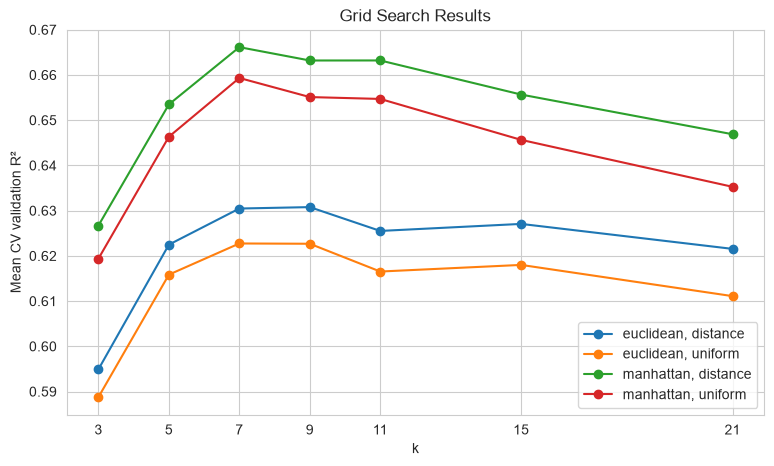

In [33]:
# Validation R² vs k for every metric/weights combination
plt.figure(figsize=(9, 5))
for (metric, weight), group in results_df.groupby(['distance_metric', 'weights']):
    group = group.sort_values('k')
    plt.plot(group['k'], group['cv_val_r2'], marker='o', label=f'{metric}, {weight}')
plt.xlabel('k')
plt.ylabel('Mean CV validation R²')
plt.title('Grid Search Results')
plt.xticks(param_grid['k'])
plt.legend()
plt.show()

**Patterns:**
- **Manhattan beats Euclidean** for every k. Euclidean squares the differences, so one feature with a big difference can dominate the distance. Manhattan treats all feature differences more evenly, which helps with 14 features of mixed usefulness.
- **Distance weighting helps a little**, because the closest neighbors are usually the most similar houses.
- Validation R² rises from k=3, peaks around a **middle k**, and then slowly drops as the neighborhoods get too big and start averaging in less similar houses.
- Note that with **distance weighting, training R² is 1.0**. Each training point is its own neighbor at distance 0, so it predicts itself perfectly. That's why the validation score is the one that matters.

## 5.3 Performance Analysis
### 1. Learning Curves (training vs validation R² vs k)

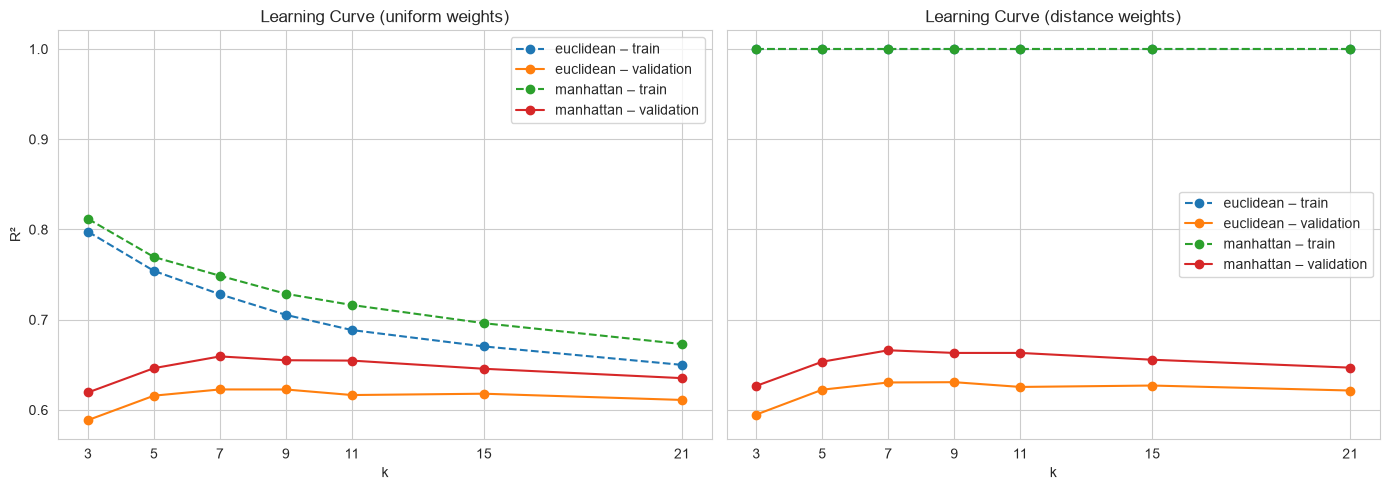

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, weight in zip(axes, ['uniform', 'distance']):
    for metric in ['euclidean', 'manhattan']:
        g = results_df[(results_df['weights'] == weight) & (results_df['distance_metric'] == metric)].sort_values('k')
        ax.plot(g['k'], g['train_r2'], marker='o', linestyle='--', label=f'{metric} – train')
        ax.plot(g['k'], g['cv_val_r2'], marker='o', label=f'{metric} – validation')
    ax.set_title(f'Learning Curve ({weight} weights)')
    ax.set_xlabel('k')
    ax.set_xticks(param_grid['k'])
    ax.legend()
axes[0].set_ylabel('R²')
plt.tight_layout()
plt.show()

With **uniform** weights, a small k gives high training R² but lower validation R². That's **overfitting / high variance**: the model follows the noise of a few points. As k grows, the training score falls and the gap closes, so the model gets smoother. If k is too large it would **underfit (high bias)**. The best balance is the k with the highest validation R².

### 2. Distance Metric Comparison

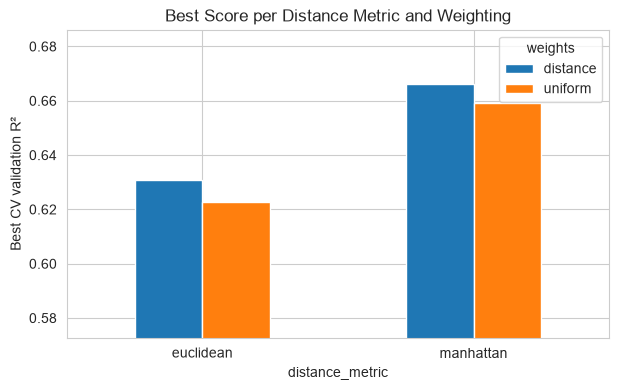

weights,distance,uniform
distance_metric,,
euclidean,0.631,0.623
manhattan,0.666,0.659


In [35]:
best_per_combo = results_df.groupby(['distance_metric', 'weights'])['cv_val_r2'].max().unstack()
ax = best_per_combo.plot(kind='bar', figsize=(7, 4), rot=0)
ax.set_ylabel('Best CV validation R²')
ax.set_title('Best Score per Distance Metric and Weighting')
ax.set_ylim(best_per_combo.values.min() - 0.05, best_per_combo.values.max() + 0.02)
plt.show()
best_per_combo

### 3. Feature Importance (permutation method)
k-NN has no built-in feature importances. To estimate which features matter most for picking neighbors, I **shuffle one feature at a time** in the hold-out set and measure how much R² drops. A big drop means the model relies heavily on that feature.

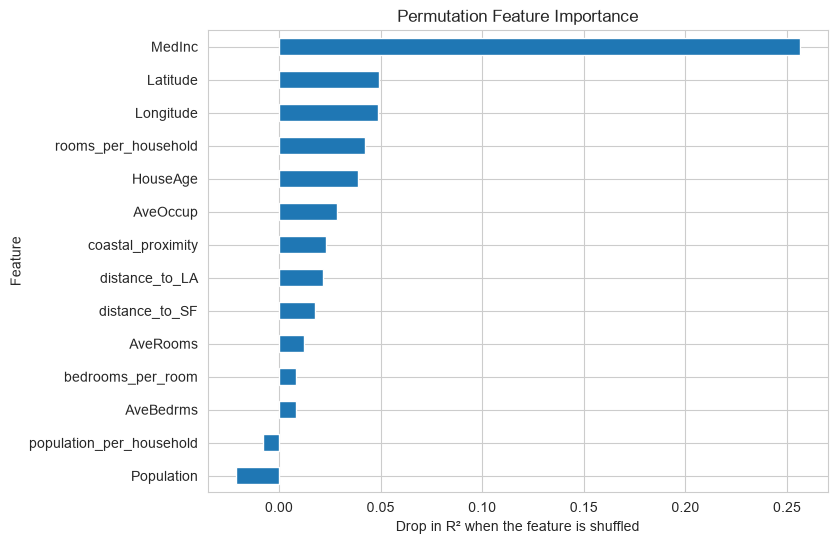

,Feature,R² drop
0,MedInc,0.256
6,Latitude,0.049
7,Longitude,0.048
8,rooms_per_household,0.042
1,HouseAge,0.039
5,AveOccup,0.028
13,coastal_proximity,0.023
11,distance_to_LA,0.022
12,distance_to_SF,0.018
2,AveRooms,0.012


In [36]:
best_model = CustomKNN(**best_params).fit(X_gs, y_gs)
base_score = best_model.score(X_hold, y_hold)

rng = np.random.RandomState(RANDOM_STATE)
importances = []
for j, name in enumerate(model_features):
    X_perm = X_hold.copy()
    X_perm[:, j] = rng.permutation(X_perm[:, j])  # shuffle one column to break its link with the target
    importances.append(base_score - best_model.score(X_perm, y_hold))

importance_df = pd.DataFrame({'Feature': model_features, 'R² drop': importances}).sort_values('R² drop')
importance_df.plot(x='Feature', y='R² drop', kind='barh', figsize=(8, 6), legend=False)
plt.title('Permutation Feature Importance')
plt.xlabel('Drop in R² when the feature is shuffled')
plt.show()
importance_df.sort_values('R² drop', ascending=False)

**Interpretation:** `MedInc` is by far the most important feature, which matches the EDA. Next come the **location** features (`Latitude`, `Longitude`, distances to LA/SF), then `rooms_per_household` and `HouseAge`. `Population` and `population_per_household` have a **negative** drop: shuffling them made the model slightly *better*. They only add noise to the distance and are good candidates to remove (feature selection).

### 4. Error Analysis (final model on the test set)
The best parameters are now used with the **full** training set to predict the untouched test set.

In [37]:
final_model = CustomKNN(**best_params).fit(X_train, y_train)

start = time.time()
y_pred = final_model.predict(X_test)
custom_time = time.time() - start

residuals = y_test - y_pred
test_r2 = 1 - np.sum(residuals ** 2) / np.sum((y_test - y_test.mean()) ** 2)
print('Final parameters:', best_params)
print(f'Test R²:   {test_r2:.4f}')
print(f'Test RMSE: {np.sqrt(np.mean(residuals ** 2)):.4f}  (${np.sqrt(np.mean(residuals ** 2)) * 100000:,.0f})')
print(f'Test MAE:  {np.mean(np.abs(residuals)):.4f}  (${np.mean(np.abs(residuals)) * 100000:,.0f})')
print(f'Prediction time on {len(X_test)} test points: {custom_time:.1f} s')

Final parameters: {'k': 7, 'distance_metric': 'manhattan', 'weights': 'distance'}
Test R²:   0.7269
Test RMSE: 0.5802  ($58,021)
Test MAE:  0.3914  ($39,144)
Prediction time on 3959 test points: 15.4 s


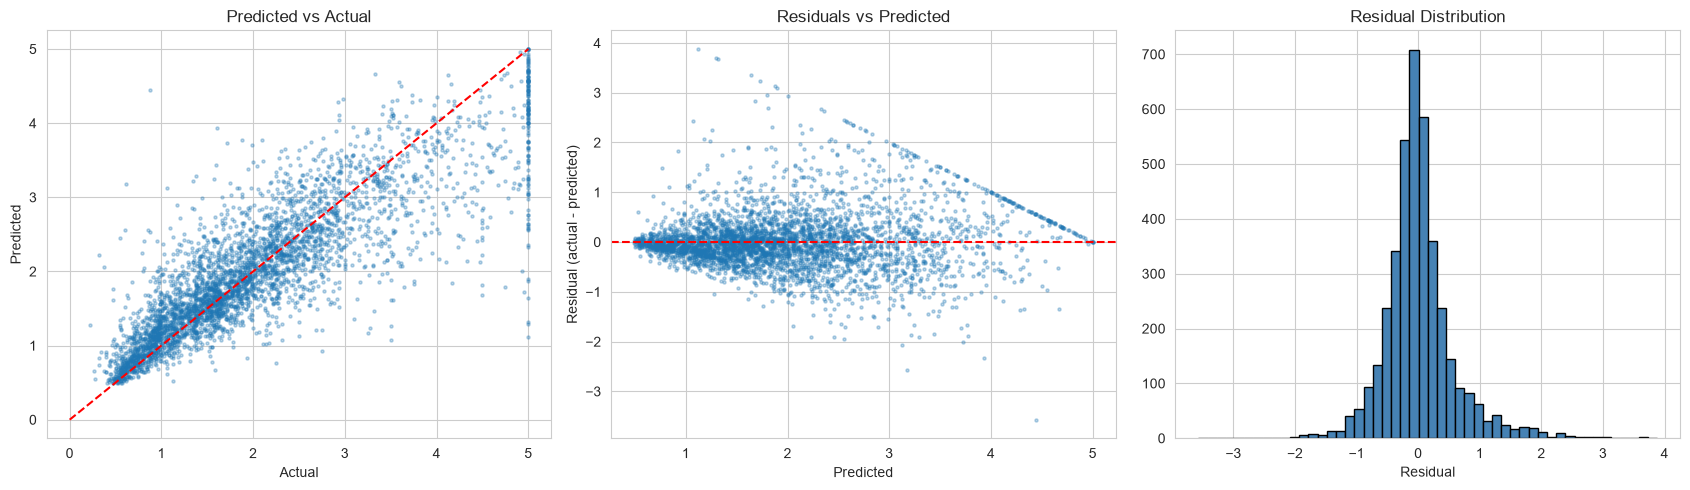

,Mean residual,MAE,Count
Price range ($100k),,,
<1,-0.238,0.261,758
1-2,-0.162,0.302,1573
2-3,0.051,0.380,983
3-4,0.378,0.569,359
4-5+,1.035,1.044,286


In [38]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(y_test, y_pred, s=5, alpha=0.3)
axes[0].plot([0, 5], [0, 5], 'r--')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title('Predicted vs Actual')

axes[1].scatter(y_pred, residuals, s=5, alpha=0.3)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Residual (actual - predicted)')
axes[1].set_title('Residuals vs Predicted')

axes[2].hist(residuals, bins=50, color='steelblue', edgecolor='black')
axes[2].set_xlabel('Residual')
axes[2].set_title('Residual Distribution')
plt.tight_layout()
plt.show()

# Average error by actual price range
price_bins = pd.cut(y_test, bins=[0, 1, 2, 3, 4, 5.1], labels=['<1', '1-2', '2-3', '3-4', '4-5+'])
pd.DataFrame({'Price range ($100k)': price_bins, 'Residual': residuals}).groupby(
    'Price range ($100k)', observed=True)['Residual'].agg(['mean', lambda r: np.mean(np.abs(r)), 'count']).rename(
    columns={'mean': 'Mean residual', '<lambda_0>': 'MAE', 'count': 'Count'})

**Error patterns:**
- Residuals are centered around 0, with a roughly bell-shaped distribution.
- The model **over-predicts cheap homes** (negative mean residual) and **under-predicts expensive homes** (positive mean residual). k-NN averages neighbors, which pulls predictions toward the middle.
- The worst errors are at the **\$500k cap**. Their true value is ≥ \$500k, and an average of neighbors almost never reaches 5.0. The diagonal line of points in the residual plot comes from these capped homes.

---
# Part 6: Comparison and Advanced Analysis
## 6.1 Sklearn Comparison
I compare `CustomKNN` with sklearn's `KNeighborsRegressor` using the same parameters and data. `algorithm='brute'` makes sklearn compare against every point too, the same way my version does.

In [39]:
comparison = []
for metric in ['euclidean', 'manhattan']:
    for weight in ['uniform', 'distance']:
        k = best_params['k']
        custom = CustomKNN(k=k, distance_metric=metric, weights=weight).fit(X_gs, y_gs)
        sk = KNeighborsRegressor(n_neighbors=k, metric=metric, weights=weight, algorithm='brute').fit(X_gs, y_gs)
        custom_pred = custom.predict(X_hold)
        sk_pred = sk.predict(X_hold)
        comparison.append({
            'k': k, 'metric': metric, 'weights': weight,
            'custom_r2': custom.score(X_hold, y_hold),
            'sklearn_r2': sk.score(X_hold, y_hold),
            'max_abs_diff': np.max(np.abs(custom_pred - sk_pred)),
            'match (allclose)': np.allclose(custom_pred, sk_pred),
        })
pd.DataFrame(comparison)

,k,metric,weights,custom_r2,sklearn_r2,max_abs_diff,match (allclose)
0,7,euclidean,uniform,0.662,0.662,0.000,True
1,7,euclidean,distance,0.666,0.666,0.000,True
2,7,manhattan,uniform,0.682,0.682,0.000,True
3,7,manhattan,distance,0.688,0.688,0.000,True


In [40]:
# Speed comparison on the full train/test sets with the best parameters
sk_final = KNeighborsRegressor(n_neighbors=best_params['k'], metric=best_params['distance_metric'],
                               weights=best_params['weights']).fit(X_train, y_train)
start = time.time()
sk_test_pred = sk_final.predict(X_test)
sk_time = time.time() - start

print(f'CustomKNN test R²: {test_r2:.4f}   time: {custom_time:.2f} s')
print(f'sklearn   test R²: {sk_final.score(X_test, y_test):.4f}   time: {sk_time:.2f} s')
print(f'sklearn is about {custom_time / sk_time:.0f}x faster')
print('Predictions match:', np.allclose(y_pred, sk_test_pred))

CustomKNN test R²: 0.7269   time: 15.39 s


sklearn   test R²: 0.7269   time: 0.63 s
sklearn is about 24x faster
Predictions match: True


**Results:** my implementation gives the **same predictions** as sklearn for all four metric/weight combinations (max difference 0, up to floating-point rounding), and the same test R², so the logic is correct. The difference is **speed**. My version loops over test points in Python and sorts all distances each time. sklearn uses optimized compiled code and tree structures (KD-tree / Ball-tree) to avoid checking every point, so it is much faster.

## 6.2 Curse of Dimensionality
I create random data where the target depends **only on the first feature** (plus a little noise). Every extra dimension is pure noise. As dimensions are added, I measure:
1. k-NN test R² (sklearn, k=5)
2. The average ratio of **nearest distance ÷ farthest distance**. A ratio close to 1 means "nearest" and "farthest" are about the same distance away, so the idea of a "close neighbor" stops making sense.

 Dimensions  Test R²  Nearest/Farthest ratio
          1    0.880                   0.001
          2    0.872                   0.017
          5    0.827                   0.128
         10    0.734                   0.274
         20    0.513                   0.427
         50    0.393                   0.595
        100    0.208                   0.703


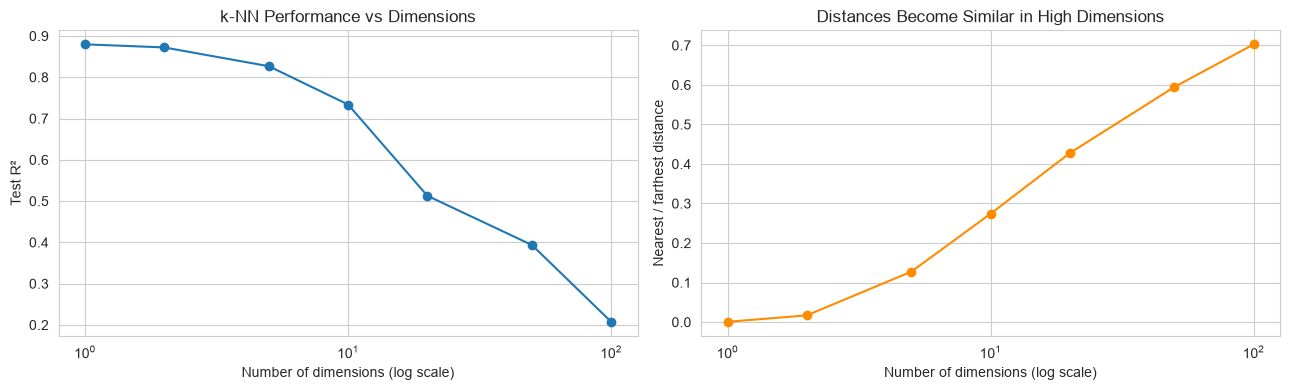

In [41]:
dims = [1, 2, 5, 10, 20, 50, 100]
n_samples = 1000
rng = np.random.RandomState(RANDOM_STATE)

dim_r2, dim_ratio = [], []
for d in dims:
    X_syn = rng.rand(n_samples, d)                            # random uniform data in d dimensions
    y_syn = X_syn[:, 0] + 0.1 * rng.randn(n_samples)          # target depends only on feature 0
    Xtr, Xte, ytr, yte = train_test_split(X_syn, y_syn, test_size=0.2, random_state=RANDOM_STATE)

    model = KNeighborsRegressor(n_neighbors=5).fit(Xtr, ytr)
    dim_r2.append(model.score(Xte, yte))

    # For each test point: nearest / farthest training distance, then average
    ratios = []
    for q in Xte:
        dist = euclidean_distance(Xtr, q)
        ratios.append(dist.min() / dist.max())
    dim_ratio.append(np.mean(ratios))

print(pd.DataFrame({'Dimensions': dims, 'Test R²': dim_r2, 'Nearest/Farthest ratio': dim_ratio}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(dims, dim_r2, marker='o')
axes[0].set_xscale('log')
axes[0].set_xlabel('Number of dimensions (log scale)')
axes[0].set_ylabel('Test R²')
axes[0].set_title('k-NN Performance vs Dimensions')
axes[1].plot(dims, dim_ratio, marker='o', color='darkorange')
axes[1].set_xscale('log')
axes[1].set_xlabel('Number of dimensions (log scale)')
axes[1].set_ylabel('Nearest / farthest distance')
axes[1].set_title('Distances Become Similar in High Dimensions')
plt.tight_layout()
plt.show()

**Discussion:** with 1–2 dimensions, k-NN predicts well. As more noise dimensions are added, R² drops steadily, from about 0.88 at 1 dimension to about 0.21 at 100, even though the useful signal never changed. The nearest/farthest ratio climbs toward 1: in high dimensions every point is roughly the same distance from every other point, so the "nearest" neighbors are no longer actually similar.

**Implications for feature selection:** for k-NN, every feature counts equally in the distance, so **useless features actively hurt** the model. They drown out the useful ones. That's why it matters to keep only informative features (like `MedInc` and location, per the permutation importance in 5.3), reduce dimensions (e.g. PCA), or weight features. Adding more features is not automatically better.

---
# Conceptual Questions

**1. Why might Manhattan distance be preferable to Euclidean distance in certain scenarios?**
Euclidean squares each difference, so one feature with a large difference can dominate the whole distance. Manhattan adds absolute differences, which makes it **less sensitive to outliers** and to a single extreme feature. It also tends to work better in **higher dimensions**, since distances stay more distinguishable. And it fits naturally when movement happens along a grid (e.g. city blocks). This matched my results: Manhattan beat Euclidean on the 14-feature housing data.

**2. How does the choice of k affect the bias-variance tradeoff in k-NN?**
A **small k** (e.g. 1–3) has **low bias but high variance**. Predictions follow individual noisy neighbors, so the model overfits. A **large k** has **high bias but low variance**. Predictions average over many neighbors and get smooth, but they miss local patterns (underfitting). In the extreme, k = n always predicts the overall mean. The best k is in between and is found with cross-validation.

**3. What are the computational implications of different distance metrics?**
Every prediction needs a distance to every training point: O(n·d) per query. **Manhattan** is the cheapest (only subtraction and absolute value). **Euclidean** adds squaring and a square root. The square root can be skipped when ranking, since it doesn't change the order. **Minkowski** with general p needs powers and a p-th root, which are the slowest. Metrics also matter for speed-up structures: KD-trees and Ball-trees work with true metrics like these, but not with every custom similarity measure.

**4. How would you modify k-NN for categorical features?**
Options include: **one-hot encode** the categories, then scale them so they don't dominate or get ignored. Use **Hamming distance** for categorical features (0 if equal, 1 if different). Or combine both types with a mixed measure such as **Gower distance**, which uses a scaled numeric difference for numeric features and a match/mismatch score for categorical ones. Ordered categories (like Low/Medium/High income) can also be encoded as numbers 0, 1, 2.

---
# Implementation Decisions

**Alternatives considered:**
- *Pure Python loops for distances* vs. *numpy vectorization:* I used numpy for one test point vs. all training points at once. It's still a from-scratch formula, just fast enough to run in Colab.
- *Full data grid search* vs. *2,000-row sample:* the full version would take hours with a from-scratch k-NN, so I tuned on a sample and evaluated the final model on the full data.
- *IQR* vs. *Z-score outlier removal:* chose Z-score because it removes far fewer valid rows (see 2.2).
- *Log transforming skewed features:* considered, but outlier removal plus StandardScaler was simpler and worked well.

**Limitations of my implementation:**
- **Slow:** each prediction sorts all n distances (O(n log n)). There's no KD-tree, and test points are handled one at a time in a Python loop.
- **Memory:** the whole training set must be kept, which is true of k-NN in general.
- Hyperparameters were tuned on a sample, so the best k might differ slightly on the full dataset.
- All features are weighted equally in the distance. There's no feature weighting or selection built in.
- Only numeric features are supported.

---
# Personal Analysis & Reflection
*(To be written in my own words.)*

**Conclusions:**
✍️ YOUR ANSWER HERE

**Surprises or unexpected findings:**
✍️ YOUR ANSWER HERE

**How this assignment changed my understanding of k-NN:**
✍️ YOUR ANSWER HERE

**What was the most challenging part of this assignment?**
✍️ YOUR ANSWER HERE

**How would I improve my approach with more time?**
✍️ YOUR ANSWER HERE

**What real-world applications could benefit from this analysis?**
✍️ YOUR ANSWER HERE

---
## Academic Integrity Statement

By submitting this assignment, I certify that:
- All code was written by me personally
- All analysis and insights are my original work
- I understand the concepts demonstrated in my implementation
- I have properly cited any external resources used
- I am prepared to explain any part of my solution in detail

**Student Signature:** ✍️ _________________________ **Date:** ✍️ _____________